# 06 — Reconstruct weekly barangay dengue allocations from annual data

**Quezon City · UPRI-NOAH + GIS settlement data · source snapshot acquired 20 November 2026**

This notebook follows the full path from original inputs to generated weekly tables:

1. Inventory and verify the raw sources; inspect schemas, duplicate keys and missing entries.
2. Compare annual barangay cases with observed QC-wide weekly cases.
3. Audit settlement attributes, polygons, identifiers, product changes and backcasts.
4. Explain and test median-based recovery of missing annual entries.
5. Construct compatible annual/weekly targets, fit an allocation with IPF, and round while conserving both margins.
6. Compare with the supplied synthetic trial, inspect sensitivity, and export auditable data.

**What the result means.** Weekly barangay counts are **modeled allocations**, not observed weekly surveillance, recovered medical records, or validated hotspot predictions. Median recovery estimates missing numbers; it cannot discover the true observations. Observed annual cases, QC weekly observations, settlement measurements, settlement backcasts and generated counts remain separate columns and artifacts. Nothing here replaces a production forecast or hospital input.

The notebook is intentionally retrospective: same-year annual totals, within-year statistics and 2010–2015 settlement backcasts use information unavailable to a forecast at that year's beginning. Model accuracy against these synthetic labels cannot establish accuracy against real weekly barangay dengue.


In [1]:
import hashlib
import importlib.metadata as metadata
import json
import platform
from pathlib import Path
import sqlite3
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

start = Path.cwd()
ROOT = next((p for p in (start, *start.parents) if (p / "services/engine/upri_data.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Start the kernel from the SurgeWise checkout or notebooks/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.generate_weekly_barangay import (
    allocate, clean_name, controlled_round, ipf, largest_remainder,
    load_inputs, median_recover, reconcile_gis, validate_calendar,
)
from services.engine.upri_data import verify_sources

EXPORT = True  # Writes derived outputs only in the final section.
OUT = ROOT / "data/processed/weekly_barangay_reconstruction"
ASSUMPTION_VERSION = "weekly-reconstruction-v1"
SEEDS = [17, 29, 43]  # Fixed before recovery-method comparison.
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 14)
versions = {p: metadata.version(p) for p in ["numpy", "pandas", "scipy", "openpyxl", "matplotlib", "shapely", "pyproj"]}
display(pd.Series({"Python": platform.python_version(), "Kernel": sys.executable, **versions}, name="Execution environment"))


Python                                                  3.13.13
Kernel        /home/lumpia/Desktop/Workspace/SurgeWise/.venv...
numpy                                                     2.5.4
pandas                                                    2.3.3
scipy                                                    1.17.1
openpyxl                                                  3.1.5
matplotlib                                               3.11.2
shapely                                                   2.2.0
pyproj                                                    3.8.0
Name: Execution environment, dtype: object

## 1. Source inventory and provenance before analysis

The linked folders contain original observations, processed tables and prior experiments. A processed file is not automatically another independent observation.

- **Pinned UPRI originals:** `data/raw/upri_noah/`; the annual CSV contains 142 barangays × 16 years and the workbook contains QC weekly cases and weather.
- **New Drive snapshots:** `data/raw/drive_dengue/` and `data/raw/drive_qc_prepared/`. Check byte equality and value equality before reusing them. `dengueweek.csv` has only dates/counts and no geographic field; its geography is not assumed from its folder.
- **GIS master:** `data/raw/gis_settlements/qc_settlement_master_2010_2025.csv` and `.gpkg`. These are supplied derived GIS outputs. They combine Evolution and Tracker measurements with an explicit product break.
- **Separate Tracker backcast:** `qc_tracker_based_annual_2010_2025.csv`; 2010–2015 are extrapolated estimates. This is the settlement scenario used by the supplied synthetic trial, not a corrected version of the original GIS master.
- **Prior synthetic trial:** `data/raw/weekly_barangay_synthetic/`; retain its original missing counts and selected beta = +0.5 scenario. Its complete original CSV is included locally for comparison.

The acquisition manifest records original Drive IDs/URLs, modification dates, byte counts and SHA-256 hashes. Folder access does not establish redistribution permission. Existing UPRI sources carry the pinned README's ODC-ODbL attribution/share-alike obligations; review GIS provider terms before redistributing any database. No raw files are edited. This snapshot selects relevant tabular/GIS inputs rather than mirroring huge rasters, unrelated PDFs or fitted models.


In [2]:
upri_manifest = verify_sources(ROOT)
drive_manifest_path = ROOT / "data/reference/weekly_barangay_reconstruction/drive-sources.json"
drive_manifest = json.loads(drive_manifest_path.read_text())
source_inventory = pd.DataFrame(drive_manifest["sources"])
for source in drive_manifest["sources"]:
    path = ROOT / source["path"]
    if not path.is_file() or hashlib.sha256(path.read_bytes()).hexdigest() != source["sha256"]:
        raise ValueError("Missing/changed acquired source: " + source["path"])
display(source_inventory[["path", "bytes", "retrievedDate", "sha256"]])
for name in ["QC_YearlyData-Barangay(CSV).csv", "Dengue_Environmental Vars_Dataset.xlsx"]:
    assert (ROOT / "data/raw/upri_noah" / name).read_bytes() == (ROOT / "data/raw/drive_dengue" / name).read_bytes()
print("Drive annual CSV and workbook are byte-identical to pinned UPRI originals; all acquired hashes match.")
annual, settlement, weekly = load_inputs(ROOT)
annual_wide = pd.read_csv(ROOT / "data/raw/upri_noah/QC_YearlyData-Barangay(CSV).csv")


,path,bytes,retrievedDate,sha256
0,data/raw/gis_settlements/qc_settlement_master_...,985278,2026-11-20,21ee79e3a812918d449f300dead26fa11b266dcbe95662...
1,data/raw/gis_settlements/RESULTS_AND_METHOD.md,7548,2026-11-20,774479baebd2265bf256fc9903469a75bfacdc5785c9e6...
2,data/raw/gis_settlements/data_dictionary.csv,1683,2026-11-20,ee740aba677754bd0701e4e24823a063b984ee12811c6d...
3,data/raw/gis_settlements/qc_settlement_master_...,704512,2026-11-20,c6bda10ba5938bab42aee36a24b369ecf459c816c056ee...
4,data/raw/gis_settlements/qc_tracker_based_annu...,964727,2026-11-20,c0d69a9fd7c81a3fe923463bd6a2564e822792ca4982f2...
5,data/raw/gis_settlements/TRACKER_BACKCAST_METH...,6529,2026-11-20,7e9e50ee7709d7fb9a55738d90f79dc502c673e85b2499...
6,data/raw/weekly_barangay_synthetic/metadata.json,1826,2026-11-20,48686f6c90cfecdd037c8df87af8d337d0bc70732990d4...
7,data/raw/weekly_barangay_synthetic/weekly_targ...,68158,2026-11-20,cd770346b14940e8826c8d125f40681ffe1c1439b3bfd3...
8,data/raw/weekly_barangay_synthetic/SELECTED_SC...,2832,2026-11-20,5a5bc51ebe60a0a9e1abec09ad6f4d30795622de37dee9...
9,data/raw/weekly_barangay_synthetic/synthetic_w...,21408125,2026-11-20,0c9316e52784aba8ad4860e5b7e903c1262c4cf8c9ecaa...


Drive annual CSV and workbook are byte-identical to pinned UPRI originals; all acquired hashes match.


## 2. Inspect the UPRI workbook and QC weekly reference

We use source keys **(YR, WN)**, not inferred dates. The UPRI dictionary calls WN ISO, while its summary/validation describes 52 blocks with rare week 53 folded into 52. Therefore this notebook requires the supplied 52-block sequence without inserting a fictional 53rd block. The ordinal is $t=52\,YR+WN-1$. A four-block rainfall lag is a shift by four records on this continuous sequence, including across year boundaries; it is not an independently verified 28-day clinical delay.

QC `DC_QC` is a city-level observed case count. `RF_NASA` is the source rainfall feature; its source name is preserved and it is not replaced with missing station rainfall. Pressure/specific-humidity gaps and station-weather blocks should be reported rather than filled automatically. The allocation needs QC cases and RF_NASA, not every workbook weather variable.


In [3]:
workbook = ROOT / "data/raw/upri_noah/Dengue_Environmental Vars_Dataset.xlsx"
book = pd.ExcelFile(workbook)
display(pd.DataFrame({"sheet": book.sheet_names, "rows": [len(pd.read_excel(book, s)) for s in book.sheet_names]}))
weekly_raw = pd.read_excel(book, "QC Data")
weather_missing = pd.DataFrame({"field": weekly_raw.columns, "missing_rows": weekly_raw.isna().sum().to_numpy()})
weather_missing["missing_fraction"] = weather_missing.missing_rows / len(weekly_raw)
display(weather_missing.loc[weather_missing.missing_rows > 0])
weekly = validate_calendar(weekly_raw)
assert len(weekly) == 16 * 52 and weekly.DC_QC.notna().all()
assert not weekly.duplicated(["YR", "WN"]).any()
qc_prepared = pd.read_csv(ROOT / "data/raw/drive_qc_prepared/qc_weekly.csv")
pd.testing.assert_frame_equal(
    weekly[["YR", "WN", "DC_QC", "RF_NASA"]].reset_index(drop=True),
    qc_prepared[["year", "source_week", "dengue_cases", "rainfall_mm"]].set_axis(["YR", "WN", "DC_QC", "RF_NASA"], axis=1),
    check_dtype=False, check_exact=False, rtol=1e-12,
)
extra = pd.read_csv(ROOT / "data/raw/drive_dengue/dengueweek.csv")
display(pd.Series({"QC_source_blocks": len(weekly), "QC_case_gaps": int(weekly.DC_QC.isna().sum()),
                   "extra_dengueweek_rows": len(extra), "extra_file_columns": list(extra.columns),
                   "extra_file_geography": "unknown; excluded from allocation"}, name="Coverage audit"))
display(extra.head())


,sheet,rows
0,Dataset Summary,47
1,Data Dictionary,37
2,QC Data,832
3,Regional Data,7072
4,Multi-Setting Data,3216


,field,missing_rows,missing_fraction
4,RF_PAGASA,572,0.687500
11,Pressure_ERA5-Land,13,0.015625
14,SH_ERA5-Land,13,0.015625
15,Temp_PAGASA,480,0.576923
16,RH_PAGASA,480,0.576923
17,VaporPressureSat_PAGASA,480,0.576923
18,VaporPressureAct_PAGASA,480,0.576923
19,SH_PAGASA,480,0.576923


QC_source_blocks                                       832
QC_case_gaps                                             0
extra_dengueweek_rows                                  572
extra_file_columns                                 [MW, n]
extra_file_geography     unknown; excluded from allocation
Name: Coverage audit, dtype: object

,MW,n
0,1/1/2012,103
1,1/8/2012,121
2,1/15/2012,128
3,1/22/2012,145
4,1/29/2012,110


## 3. Audit annual counts: null is different from zero

The 142 source codes identify QC barangays. The table has 16 annual case columns and `DC_Mean`. We reshape only the annual columns; `DC_Mean` summarizes multiple years and would leak later information in historical forecasting.

For each year, report observed counts, missing entries, valid zeros, and the known subtotal. We check keys, nonnegative integer counts and the full year-by-barangay grid. A blank may mean missing reporting, an unknown measurement, or another source issue: the dataset does not establish its mechanism. A zero remains zero. Neither dropping incomplete barangays nor filling all blanks with zero is justified.

This extract contains **no explicit annual zero counts**. That pattern does not prove that blanks mean zero. Clarifying omitted zeros versus unreported cases requires the provider; median imputation cannot resolve that semantic question.


,barangays,known_entries,known_subtotal,observed_zeros,missing_entries
year,,,,,
2010,142,139,5343.0,0,3
2011,142,140,8421.0,0,2
2012,142,139,9214.0,0,3
2013,142,141,6358.0,0,1
2014,142,130,2569.0,0,12
2015,142,140,7034.0,0,2
2016,142,140,4997.0,0,2
2017,142,142,8779.0,0,0
2018,142,141,9027.0,0,1


,barangay_code,barangay_name,year
38,PH1307404038,Escopa II,2010
60,PH1307404059,Mangga,2010
92,PH1307404087,Quirino 2-C,2010
157,PH1307404014,Bayanihan,2011
159,PH1307404016,Blue Ridge B,2011
301,PH1307404016,Blue Ridge B,2012
324,PH1307404040,Escopa IV,2012
356,PH1307404023,New Era (Constitution Hills),2012
441,PH1307404014,Bayanihan,2013
583,PH1307404014,Bayanihan,2014


Missing annual cells: 39 ; distinct affected barangays: 23


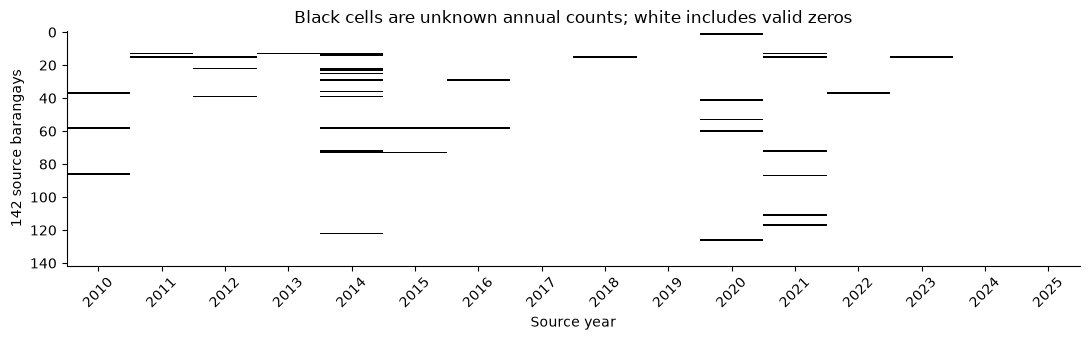

In [4]:
expected_grid = pd.MultiIndex.from_product([annual.barangay_code.unique(), range(2010, 2026)], names=["barangay_code", "year"])
actual_grid = pd.MultiIndex.from_frame(annual[["barangay_code", "year"]])
assert len(expected_grid.difference(actual_grid)) == 0
assert not annual.duplicated(["barangay_code", "year"]).any()
annual_audit = annual.groupby("year").agg(
    barangays=("barangay_code", "size"), known_entries=("annual_cases", "count"),
    known_subtotal=("annual_cases", lambda s: s.sum(min_count=1)),
    observed_zeros=("annual_cases", lambda s: int(s.eq(0).sum())),
)
annual_audit["missing_entries"] = annual_audit.barangays - annual_audit.known_entries
missing_annual = annual.loc[annual.annual_cases.isna(), ["barangay_code", "barangay_name", "year"]].copy()
display(annual_audit)
display(missing_annual)
print("Missing annual cells:", len(missing_annual), "; distinct affected barangays:", missing_annual.barangay_code.nunique())
missing_matrix = annual.pivot(index="barangay_code", columns="year", values="annual_cases").isna()
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.imshow(missing_matrix, aspect="auto", interpolation="nearest", cmap="Greys", vmin=0, vmax=1)
ax.set(xticks=range(16), xticklabels=range(2010, 2026), xlabel="Source year", ylabel="142 source barangays",
       title="Black cells are unknown annual counts; white includes valid zeros")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()


## 4. Reconcile the incompatible annual totals before generating weeks

Let $A_{b,y}$ be the known annual count for barangay $b$, $C_{y,w}$ the observed city count, $B_y$ the barangays with available annual counts, $T_y=\sum_{b\in B_y}A_{b,y}$, and $Q_y=\sum_w C_{y,w}$.

If a matrix $X_{b,w}$ preserves every annual row and every city weekly column, summing it both ways requires $T_y=Q_y$. The data violate this equality. Missingness alone does not explain years where the **known subtotal already exceeds** the full city total. We cannot identify the reason or correct either observation series from these files.

Two transparent policies are possible:

- **Annual-preserving trial (implemented):** retain each available $A_{b,y}$ and use scaled weekly targets $c^*_{y,w}\approx C_{y,w}T_y/Q_y$, rounded to integers with sum $T_y$. These are scenario targets, not QC weekly observations. Unknown barangays stay null in the first scenario.
- **QC-preserving allocation (explained alternative):** retain $C_{y,w}$ and use scaled row weights $r^*_{b,y}\approx A_{b,y}Q_y/T_y$. The annual rows then cease to equal their observations. If unknown barangays are excluded, this additionally assumes their share can be redistributed; it is not chosen here.

Median imputation changes the scenario annual total and requires recalculating all scaled weekly targets. It cannot resolve cross-source incompatibility or turn a scenario into observed data.


,barangays,known_entries,known_subtotal,observed_zeros,missing_entries,qc_observed_total,known_minus_qc,weekly_scale_factor
year,,,,,,,,
2010,142,139,5343.0,0,3,3667,1676.0,1.457049
2011,142,140,8421.0,0,2,5538,2883.0,1.520585
2012,142,139,9214.0,0,3,7081,2133.0,1.301229
2013,142,141,6358.0,0,1,5521,837.0,1.151603
2014,142,130,2569.0,0,12,2641,-72.0,0.972738
2015,142,140,7034.0,0,2,6598,436.0,1.066081
2016,142,140,4997.0,0,2,4459,538.0,1.120655
2017,142,142,8779.0,0,0,7527,1252.0,1.166335
2018,142,141,9027.0,0,1,8158,869.0,1.106521


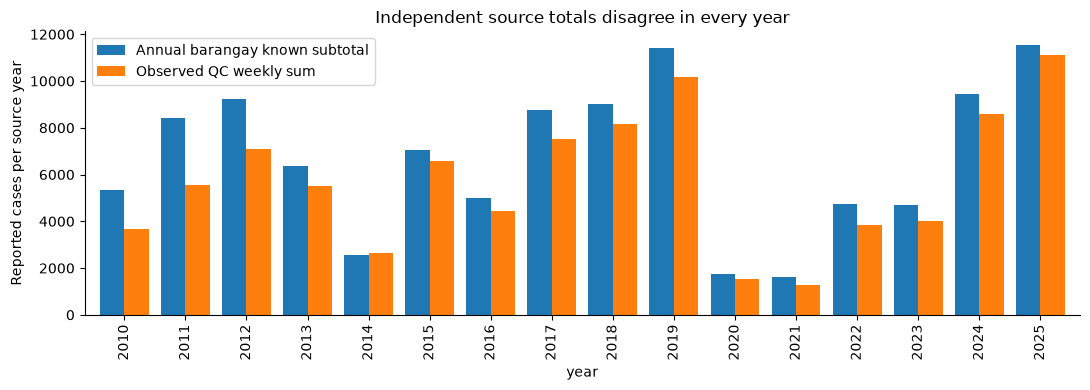

In [5]:
city_totals = weekly.groupby("YR").DC_QC.sum()
reconciliation = annual_audit.join(city_totals.rename("qc_observed_total"))
reconciliation["known_minus_qc"] = reconciliation.known_subtotal - reconciliation.qc_observed_total
reconciliation["weekly_scale_factor"] = reconciliation.known_subtotal / reconciliation.qc_observed_total
display(reconciliation)
assert reconciliation.known_minus_qc.ne(0).all()
fig, ax = plt.subplots()
reconciliation[["known_subtotal", "qc_observed_total"]].plot.bar(ax=ax, width=.8)
ax.set(ylabel="Reported cases per source year", title="Independent source totals disagree in every year")
ax.legend(["Annual barangay known subtotal", "Observed QC weekly sum"])
plt.tight_layout(); plt.show()


## 5. GIS settlement audit: area, source changes, identifiers and availability

Mapped settlement proportion is
$$p_{b,y}=\frac{\operatorname{area}(\text{mapped settlement at cutoff }y\cap\text{barangay }b)}{\operatorname{area}(\text{barangay }b)}.$$
Areas use projected **EPSG:32651**, in square metres; geographic coordinates use EPSG:4326 only for bounds checks/display. The supplied extraction uses boundary-clipped areas, not the number of pixels times an assumed area. Background or no detected settlement does not establish uninhabited land. Settlement extent is not population, household occupancy or a validated dengue-risk coefficient.

The master joins **WSF Evolution** (2010–2015, nominal 30 m) and **WSF Tracker** (2016–2025, nominal 10 m). Their 2015→2016 difference is a product discontinuity, not proven physical settlement loss. The annual Tracker label $y$ represents the **following January 1** snapshot; it is not a predictor known at the start of year $y$. See the [provider's Tracker documentation](https://source.coop/mindearth/wsf) and the preserved `RESULTS_AND_METHOD.md` for extraction details.

Two barangays have source-null official codes in all 16 years: Doña Imelda and Doña Josefa. Reuse the repository's explicit, unique project name crosswalk and retain source-null codes. Median imputation is inappropriate for identifiers, geometries and categorical quality flags. CSV mojibake is repaired only for reversible name comparison; originals remain unchanged.


In [6]:
gis_master = pd.read_csv(ROOT / "data/raw/gis_settlements/qc_settlement_master_2010_2025.csv")
tracker_source = pd.read_csv(ROOT / "data/raw/gis_settlements/qc_tracker_based_annual_2010_2025.csv")
crosswalk_records = json.loads((ROOT / "data/reference/upri_noah/barangay-crosswalk.json").read_text())["records"]
crosswalk = {r["sourceADM4_EN"]: r["ADM4_PCODE"] for r in crosswalk_records}
gis_joined = reconcile_gis(gis_master, annual_wide, crosswalk)
assert len(gis_joined) == 142 * 16
assert gis_joined.groupby("year").size().eq(142).all()
assert np.isfinite(gis_joined[["barangay_area_m2", "settlement_area_m2", "settlement_proportion"]]).all().all()
assert gis_joined.barangay_area_m2.gt(0).all()
assert gis_joined.settlement_proportion.between(-1e-12, 1 + 1e-12).all()
np.testing.assert_allclose(gis_joined.settlement_area_m2 / gis_joined.barangay_area_m2, gis_joined.settlement_proportion, atol=1e-12)
np.testing.assert_allclose(gis_joined.settlement_percent, gis_joined.settlement_proportion * 100, atol=1e-10)
area_spread = gis_joined.groupby("barangay_code").barangay_area_m2.agg(["min", "max"])
# CSV serialization differs by 2.91e-11 m² for West Kamias; do not require bit equality.
assert (area_spread["max"] - area_spread["min"]).max() < 1e-6
display(gis_joined.loc[gis_joined.source_barangay_code.isna(),
    ["barangay_name", "barangay_code", "source_barangay_code", "identifier_method"]].drop_duplicates())
gis_missing = pd.DataFrame({"master_missing": gis_master.isna().sum(), "tracker_scenario_missing": tracker_source.isna().sum()}).fillna(0).astype(int)
display(gis_missing.loc[gis_missing.sum(axis=1) > 0])
master_city = gis_joined.groupby(["year", "source_product"]).agg(mapped_m2=("settlement_area_m2", "sum"), area_m2=("barangay_area_m2", "sum"))
master_city["area_weighted_percent"] = 100 * master_city.mapped_m2 / master_city.area_m2
display(master_city)


,barangay_name,barangay_code,source_barangay_code,identifier_method
32,Doña Imelda,PH1307404031,NaN,explicit_project_name_crosswalk
33,Doña Josefa,PH1307404032,NaN,explicit_project_name_crosswalk


,master_missing,tracker_scenario_missing
actual_snapshot_date,0,852
anchor_label_year,0,1420
annual_slope_percentage_points,0,1420
barangay_code,32,32
constant_2016_sensitivity_percent,0,1420
training_years,0,1420


,,mapped_m2,area_m2,area_weighted_percent
year,source_product,,,
2010,WSF Evolution v1,1.293766e+08,1.624846e+08,79.623930
2011,WSF Evolution v1,1.294491e+08,1.624846e+08,79.668520
2012,WSF Evolution v1,1.295917e+08,1.624846e+08,79.756283
2013,WSF Evolution v1,1.296726e+08,1.624846e+08,79.806106
2014,WSF Evolution v1,1.297221e+08,1.624846e+08,79.836530
2015,WSF Evolution v1,1.298413e+08,1.624846e+08,79.909906
2016,WSF Tracker GeoZarr,7.796130e+07,1.624846e+08,47.980727
2017,WSF Tracker GeoZarr,7.859267e+07,1.624846e+08,48.369301
2018,WSF Tracker GeoZarr,7.915740e+07,1.624846e+08,48.716859


### 5.1 Inspect the actual polygon file without editing it

The local GeoPackage supplies the same 142 boundary geometries used by the GIS tables. Read SQLite in read-only mode, decode its geometry payloads, check polygon validity and projected areas, then transform only bounds for geographic sanity checks. This validates consistency of supplied outputs; it does **not** rerun satellite classification or validate the raw imagery. Original raster processing is documented in the preserved upstream method, and no historical boundary-change reconstruction is available.


,table_name,data_type,srs_id
0,barangay_annual_settlement,features,32651


valid_polygons                                               142
source_missing_codes                                           2
CRS                                                   EPSG:32651
longitude_bounds         [120.98981743500008, 121.1349717920001]
latitude_bounds         [14.589617128000048, 14.777701209000035]
Name: Geometry audit, dtype: object

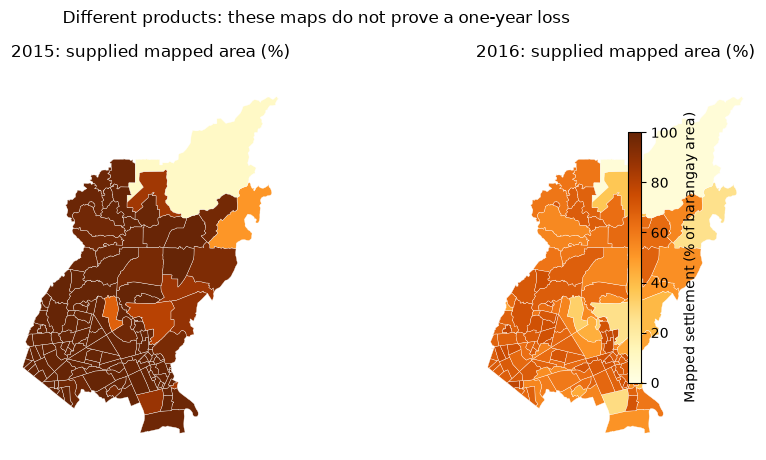

In [7]:
from shapely import from_wkb, transform
from pyproj import Transformer
from matplotlib.collections import PolyCollection

gpkg = ROOT / "data/raw/gis_settlements/qc_settlement_master_2010_2025.gpkg"
with sqlite3.connect(gpkg.as_uri() + "?mode=ro", uri=True) as conn:
    layers = pd.read_sql_query("SELECT table_name, data_type, srs_id FROM gpkg_contents", conn)
    polygons = pd.read_sql_query('SELECT fid, geom, ADM4_EN, ADM4_PCODE, barangay_area_m2 FROM barangay_annual_settlement', conn)
display(layers)
assert layers.srs_id.tolist() == [32651]
def decode_gpkg(blob):
    assert blob[:2] == b"GP"
    envelope = (blob[3] >> 1) & 7
    envelope_bytes = {0: 0, 1: 32, 2: 48, 3: 48, 4: 64}[envelope]
    return from_wkb(blob[8 + envelope_bytes:])
geometries = [decode_gpkg(v) for v in polygons.geom]
assert len(geometries) == 142 and all(g.is_valid and not g.is_empty for g in geometries)
np.testing.assert_allclose([g.area for g in geometries], polygons.barangay_area_m2, atol=.01, rtol=1e-8)
to_wgs84 = Transformer.from_crs(32651, 4326, always_xy=True).transform
bounds = np.array([transform(g, to_wgs84, interleaved=False).bounds for g in geometries])
assert (bounds[:, [0, 2]] > 120).all() and (bounds[:, [0, 2]] < 122).all()
assert (bounds[:, [1, 3]] > 14).all() and (bounds[:, [1, 3]] < 15).all()
display(pd.Series({"valid_polygons": len(geometries), "source_missing_codes": int(polygons.ADM4_PCODE.isna().sum()),
                   "CRS": "EPSG:32651", "longitude_bounds": [bounds[:, 0].min(), bounds[:, 2].max()],
                   "latitude_bounds": [bounds[:, 1].min(), bounds[:, 3].max()]}, name="Geometry audit"))
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, year in zip(axes, [2015, 2016]):
    lookup = gis_master.loc[gis_master.year == year].set_index("barangay_name").settlement_percent
    vertices, values = [], []
    for name, geom in zip(polygons.ADM4_EN, geometries):
        for part in geom.geoms:
            vertices.append(np.array(part.exterior.coords)); values.append(lookup.loc[name])
    collection = PolyCollection(vertices, array=np.array(values), cmap="YlOrBr", edgecolors="white", linewidths=.25)
    collection.set_clim(0, 100); ax.add_collection(collection); ax.autoscale_view(); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{year}: supplied mapped area (%)")
fig.colorbar(collection, ax=axes, label="Mapped settlement (% of barangay area)", shrink=.65)
fig.suptitle("Different products: these maps do not prove a one-year loss", y=.99)
fig.subplots_adjust(top=.85)
plt.show()


### 5.2 Why the Tracker backcast is a separate assumption

The existing weekly trial uses the Tracker-only scenario. For each barangay, its supplied method fits a 2016–2025 slope
$$\hat m_b=\frac{\sum_y(y-\bar y)(p_{b,y}-\bar p_b)}{\sum_y(y-\bar y)^2}$$
and extrapolates from the observed earliest anchor:
$$\hat p_{b,y}=\operatorname{clip}\{p_{b,2016}+\hat m_b(y-2016),0,1\},\quad y<2016.$$
The slope and anchor use later information. A smoother series is not evidence of accurate pre-2016 conditions. There are 852 extrapolated barangay-years and 1,420 preserved satellite-derived rows; blank `actual_snapshot_date` on extrapolated rows is **structural missingness**, not a date to median-fill. Trend fields blank on preserved rows are likewise not missing settlement measurements.

The plot compares city area-weighted coverage, $100\sum_b a_{b,y}/\sum_b a_b$. An unweighted mean would give small and large barangays equal influence. The numerical checks below independently reconstruct the backcast and compare preserved post-2016 proportions; they do not validate historical truth.


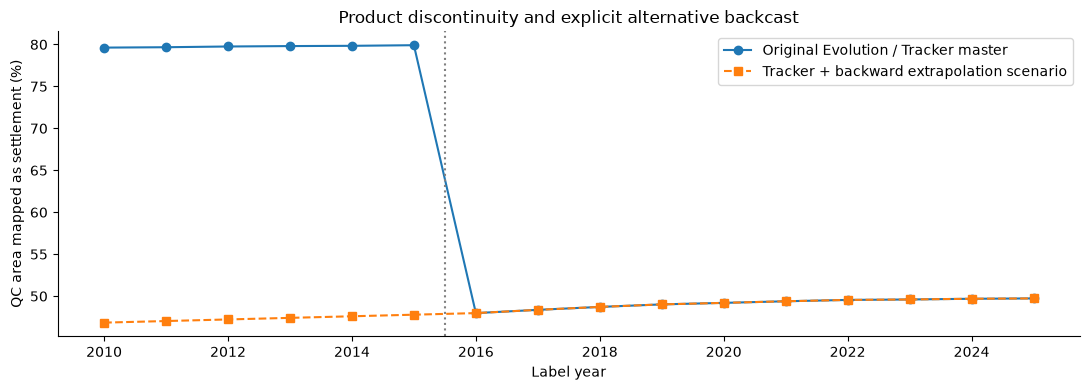

value_status
satellite_derived        1420
extrapolated_estimate     852
Name: barangay_year_rows, dtype: int64

In [8]:
tracker = reconcile_gis(tracker_source, annual_wide, crosswalk)
trend_checks = []
for b, group in tracker.groupby("barangay_code"):
    observed = group.loc[group.year >= 2016].sort_values("year")
    x, y = observed.year.to_numpy(), observed.settlement_proportion.to_numpy()
    slope = np.sum((x-x.mean())*(y-y.mean())) / np.sum((x-x.mean())**2)
    earlier = group.loc[group.year < 2016]
    prediction = np.clip(y[0] + slope * (earlier.year.to_numpy() - 2016), 0, 1)
    trend_checks.extend(np.abs(prediction - earlier.settlement_proportion.to_numpy()))
assert max(trend_checks) < 1e-12
joined_products = gis_joined.merge(tracker, on=["barangay_code", "year"], suffixes=("_master", "_tracker"), validate="one_to_one")
recent = joined_products.loc[joined_products.year >= 2016]
np.testing.assert_allclose(recent.settlement_proportion_master, recent.settlement_proportion_tracker, atol=1e-12)
tracker_city = tracker.groupby("year").agg(mapped_m2=("settlement_area_m2", "sum"), area_m2=("barangay_area_m2", "sum"))
tracker_city["percent"] = 100 * tracker_city.mapped_m2 / tracker_city.area_m2
fig, ax = plt.subplots()
ax.plot(master_city.reset_index().year, master_city.area_weighted_percent.to_numpy(), "o-", label="Original Evolution / Tracker master")
ax.plot(tracker_city.index, tracker_city.percent, "s--", label="Tracker + backward extrapolation scenario")
ax.axvline(2015.5, color="grey", linestyle=":")
ax.set(xlabel="Label year", ylabel="QC area mapped as settlement (%)", title="Product discontinuity and explicit alternative backcast")
ax.legend(); plt.tight_layout(); plt.show()
display(tracker.value_status.value_counts().rename("barangay_year_rows"))


## 6. Missing annual data: median recovery with an explicit donor ledger

### 6.1 Direct within-barangay median

For a missing $A_{b,y}$, use other **observed** annual counts from the same barangay:
$$\hat A^{\text{count}}_{b,y}=\operatorname{median}\{A_{b,t}: A_{b,t}\text{ is observed},\ t\in D\}.$$
A median minimizes $\sum_{t\in D}|A_{b,t}-a|$. It is less sensitive than a mean to isolated extreme donor values, but it can suppress real outbreak peaks and ignore long-term change. For example, donors $[0,10,20,1000]$ give median $15$ versus mean $257.5$. The zero is a valid donor. For integer scenario totals, use nearest integer with halves rounded up: $\lfloor\hat A+0.5\rfloor$. Keep the unrounded value, donor years/count and interquartile range (IQR).

Require at least **three observed donor years** (an explicit methodological choice, not a statistical guarantee). Donors come from the original table only; do not chain one imputed value into another. If insufficient donors exist, leave the entry unknown. An all-missing barangay cannot be reconstructed from its own median.

### 6.2 City-normalized median as a sensitivity comparison

Different years have different citywide burdens. A second option is
$$\hat A^{\text{share}}_{b,y}=Q_y\;\operatorname{median}_{t\in D}\left(\frac{A_{b,t}}{Q_t}\right).$$
This assumes a relatively stable barangay-to-city ratio; the incompatible input totals mean these are normalization ratios, not proven population risks or shares summing to one. Reject zero/missing donor denominators. This method uses the same observed donors and preserves every observed annual value. Neither method estimates missing population, a disease mechanism or missing observations exactly.

Without a cutoff, both methods use earlier **and later** donor years and are retrospective. `donor_cutoff=y-1` permits only earlier donor years; actual reporting availability still needs a separate verified publication policy. Raw identifiers, source blanks and geometry remain unchanged. IQR is descriptive donor spread, **not** a confidence or prediction interval. [NIST describes robust scale measures such as IQR and MAD](https://www.itl.nist.gov/div898/handbook/eda/section3/eda356.htm).


In [9]:
count_recovery = median_recover(annual, city_totals, method="count_median")
share_recovery = median_recover(annual, city_totals, method="share_median")
recovery_ledger = count_recovery.loc[count_recovery.annual_cases.isna()].copy()
recovery_ledger = recovery_ledger.merge(
    share_recovery[["barangay_code", "year", "annual_used", "estimate_unrounded"]],
    on=["barangay_code", "year"], suffixes=("_count", "_share"), validate="one_to_one")
assert len(recovery_ledger) == 39
assert count_recovery.annual_cases.equals(annual.annual_cases)
assert count_recovery.loc[annual.annual_cases.notna(), "annual_used"].eq(annual.loc[annual.annual_cases.notna(), "annual_cases"]).all()
display(recovery_ledger[["barangay_name", "year", "annual_used_count", "annual_used_share", "donor_count", "donor_years", "donor_iqr_scaled"]])
print("Median-imputed assumptions:", int(count_recovery.imputed.sum()), "; remaining unknown:", int(count_recovery.annual_used.isna().sum()))


,barangay_name,year,annual_used_count,annual_used_share,donor_count,donor_years,donor_iqr_scaled
0,Escopa II,2010,5.0,4.0,14,2011|2012|2013|2014|2015|2016|2017|2018|2019|2...,7.25
1,Mangga,2010,3.0,3.0,12,2011|2012|2013|2017|2018|2019|2020|2021|2022|2...,3.75
2,Quirino 2-C,2010,5.0,4.0,15,2011|2012|2013|2014|2015|2016|2017|2018|2019|2...,6.50
3,Bayanihan,2011,3.0,4.0,12,2010|2012|2015|2016|2017|2018|2019|2020|2022|2...,6.00
4,Blue Ridge B,2011,1.0,2.0,11,2010|2013|2014|2015|2016|2017|2019|2020|2022|2...,1.00
5,Blue Ridge B,2012,1.0,2.0,11,2010|2013|2014|2015|2016|2017|2019|2020|2022|2...,1.00
6,Escopa IV,2012,4.0,6.0,14,2010|2011|2013|2015|2016|2017|2018|2019|2020|2...,8.25
7,New Era (Constitution Hills),2012,4.0,5.0,14,2010|2011|2013|2015|2016|2017|2018|2019|2020|2...,5.75
8,Bayanihan,2013,3.0,4.0,12,2010|2012|2015|2016|2017|2018|2019|2020|2022|2...,6.00
9,Bayanihan,2014,3.0,2.0,12,2010|2012|2015|2016|2017|2018|2019|2020|2022|2...,6.00


Median-imputed assumptions: 39 ; remaining unknown: 0


## 7. Evaluate recovery where truth is available: deliberate masking

Actual missing values have no known truth. Evaluate only by temporarily hiding observed annual values, deriving donors after masking, and comparing estimates with the hidden originals. Each of three fixed seeds samples 10% of known rows **within each year**. All held-out rows for a replicate are removed together. The donor ledger and comparisons use no hidden values. Include a same-barangay **mean** baseline and report MAE, median absolute error and signed bias in annual cases; avoid percentage errors at valid zeros.

A second check hides sampled targets in each year 2013–2025 and permits donors only through the previous year. The QC total of the target year is allowed for the ratio method because this is annual retrospective recovery; it would be unavailable for a forecast made before that year ended.

These experiments test annual imputation under artificial missingness. Their random masks may not represent the real missingness mechanism. Replicates overlap; errors are not independent confidence intervals. No imputation method is automatically chosen as a validated winner. Weekly disease timing remains unobserved regardless of recovery scores.


,experiment,method,scored,unrecoverable,MAE_annual_cases,median_absolute_error,bias_cases
0,earlier_donors_only,count_median,179,0,28.603352,12.0,7.698324
1,earlier_donors_only,share_median,179,0,16.709497,7.0,5.379888
2,retrospective_random_mask,count_mean,657,0,25.435312,10.0,0.796043
3,retrospective_random_mask,count_median,657,0,24.649924,9.0,-4.385084
4,retrospective_random_mask,share_median,657,0,15.776256,5.0,-3.386606


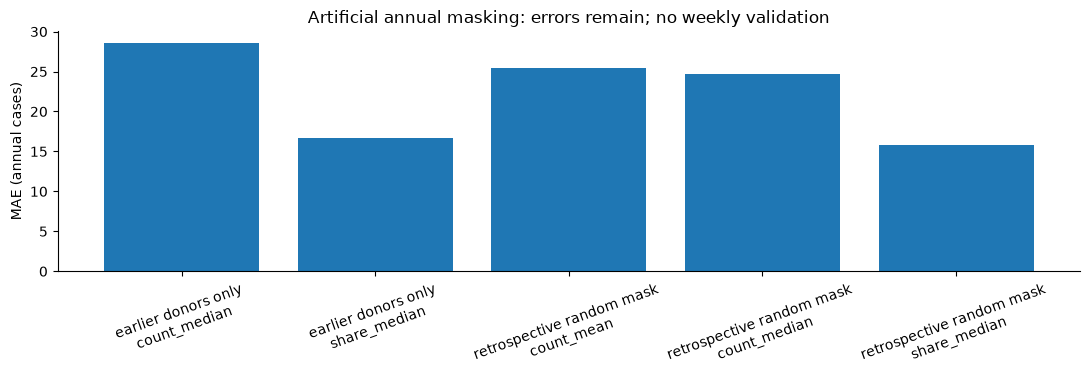

For these fixed random masks, count-median MAE is **24.65** annual cases, compared with **25.44** for the mean and **15.78** for the city-normalized median. This supports reporting the normalized method as a sensitivity comparison. It does not establish its error on the 39 actual blanks or validate any weekly timing.

In [10]:
def score_records(frame):
    out = []
    for (experiment, method), group in frame.groupby(["experiment", "method"]):
        error = group.estimate - group.truth
        out.append({"experiment": experiment, "method": method, "scored": int(error.notna().sum()),
                    "unrecoverable": int(error.isna().sum()), "MAE_annual_cases": error.abs().mean(),
                    "median_absolute_error": error.abs().median(), "bias_cases": error.mean()})
    return pd.DataFrame(out)

mask_records = []
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    selected = np.concatenate([rng.choice(g.index.to_numpy(), max(1, int(len(g) * .1)), replace=False)
                              for _, g in annual.loc[annual.annual_cases.notna()].groupby("year")])
    hidden = annual.copy(); hidden.loc[selected, "annual_cases"] = np.nan
    for method in ["count_median", "share_median"]:
        recovered = median_recover(hidden, city_totals, method=method)
        for i in selected:
            mask_records.append({"experiment": "retrospective_random_mask", "seed": seed, "method": method,
                "barangay_code": annual.loc[i, "barangay_code"], "year": int(annual.loc[i, "year"]),
                "truth": annual.loc[i, "annual_cases"], "estimate": recovered.loc[i, "annual_used"]})
    donor_means = hidden.groupby("barangay_code").annual_cases.mean()
    for i in selected:
        value = donor_means.get(annual.loc[i, "barangay_code"], np.nan)
        mask_records.append({"experiment": "retrospective_random_mask", "seed": seed, "method": "count_mean",
            "barangay_code": annual.loc[i, "barangay_code"], "year": int(annual.loc[i, "year"]),
            "truth": annual.loc[i, "annual_cases"], "estimate": np.floor(value + .5) if pd.notna(value) else np.nan})
# Identical sampled targets for each method, with future donors prohibited.
rng = np.random.default_rng(71)
for year in range(2013, 2026):
    available = annual.loc[annual.year.eq(year) & annual.annual_cases.notna()]
    selected = rng.choice(available.index.to_numpy(), max(1, int(len(available) * .1)), replace=False)
    hidden = annual.copy(); hidden.loc[selected, "annual_cases"] = np.nan
    for method in ["count_median", "share_median"]:
        recovered = median_recover(hidden, city_totals, method=method, donor_cutoff=year-1)
        for i in selected:
            mask_records.append({"experiment": "earlier_donors_only", "seed": 71, "method": method,
                "barangay_code": annual.loc[i, "barangay_code"], "year": year,
                "truth": annual.loc[i, "annual_cases"], "estimate": recovered.loc[i, "annual_used"]})
mask_predictions = pd.DataFrame(mask_records)
mask_scores = score_records(mask_predictions)
display(mask_scores)
fig, ax = plt.subplots(figsize=(11, 4))
labels = mask_scores.experiment.str.replace("_", " ") + "\n" + mask_scores.method
ax.bar(labels, mask_scores.MAE_annual_cases)
ax.set(ylabel="MAE (annual cases)", title="Artificial annual masking: errors remain; no weekly validation")
ax.tick_params(axis="x", rotation=20); plt.tight_layout(); plt.show()

random_scores = mask_scores.loc[mask_scores.experiment.eq("retrospective_random_mask")].set_index("method")
display(Markdown(f"For these fixed random masks, count-median MAE is **{random_scores.loc['count_median', 'MAE_annual_cases']:.2f}** annual cases, compared with **{random_scores.loc['count_mean', 'MAE_annual_cases']:.2f}** for the mean and **{random_scores.loc['share_median', 'MAE_annual_cases']:.2f}** for the city-normalized median. This supports reporting the normalized method as a sensitivity comparison. It does not establish its error on the 39 actual blanks or validate any weekly timing."))

## 8. Build compatible weekly targets with largest remainders

For annual total $T_y$ and observed QC total $Q_y>0$, calculate $v_w=T_y C_{y,w}/Q_y$. Start with $\lfloor v_w\rfloor$ and distribute the remaining $T_y-\sum_w\lfloor v_w\rfloor$ units to the largest fractional parts (ties follow ascending source-week order). This gives integer weekly targets summing exactly to $T_y$ while staying close to the scaled temporal profile.

Worked example: three equally weighted weeks and total 5 give $[5/3,5/3,5/3]$, floors $[1,1,1]$, then stable remainders produce **[2,2,1]**. A zero observed week receives zero target; missing QC cases block generation. If QC total is zero but annual demand is positive, temporal weights cannot be identified and generation stops. Zero annual total with valid zero case rows yields a zero allocation, not missing observations.


In [11]:
print("Hand-check: three equal weights, five cases ->", largest_remainder([1, 1, 1], 5).tolist())
example_year = 2024
example_weeks = weekly.loc[weekly.YR.eq(example_year), ["WN", "DC_QC"]].copy()
example_total = int(annual.loc[annual.year.eq(example_year), "annual_cases"].sum())
example_weeks["unrounded_scaled_target"] = example_weeks.DC_QC / example_weeks.DC_QC.sum() * example_total
example_weeks["integer_trial_target"] = largest_remainder(example_weeks.DC_QC, example_total)
display(example_weeks.head(12))
assert example_weeks.integer_trial_target.sum() == example_total


Hand-check: three equal weights, five cases -> [2, 2, 1]


,WN,DC_QC,unrounded_scaled_target,integer_trial_target
728,1,122,134.248368,134
729,2,98,107.838853,108
730,3,89,97.935285,98
731,4,87,95.734492,96
732,5,84,92.433302,92
733,6,81,89.132113,89
734,7,77,84.730527,85
735,8,68,74.826959,75
736,9,70,77.027752,77
737,10,64,70.425373,70


## 9. Construct the settlement–rainfall seed and fit both margins

For each year, standardize settlement across barangays with available annual targets and lagged city rainfall across available source blocks, using population standard deviations (`ddof=0`):
$$z^p_b=(p_b-\bar p)/s_p,\qquad z^R_w=(R_{w-4}-\bar R_{-4})/s_R.$$
A constant feature gets $z=0$. The first four records lack previous rainfall; set their **interaction** to neutral $z^R=0$ and keep a missing-lag flag and null raw rainfall. This is not rainfall imputation. The lag crosses year boundaries without wrapping the first year to future data.

The positive seed is
$$K_{b,w}=\exp\{\beta z^p_b z^R_w\}.$$
The supplied trial selects $\beta=+0.5$ and lag 4 as assumptions. A positive coefficient changes relative temporal allocation; it does not imply a 50% disease increase or establish causality. A multiplicative seed $a_b d_w$ alone would be absorbed by fixed margins. The **interaction** is what can change the fitted cross-pattern. For $\beta=0$, the solution is the independence allocation $X_{b,w}=A_b c^*_w/T$.

Iterative proportional fitting (IPF) alternates:
$$X_{b,w}\leftarrow X_{b,w}\frac{A_b}{\sum_v X_{b,v}},\qquad
X_{b,w}\leftarrow X_{b,w}\frac{c^*_w}{\sum_j X_{j,w}}.$$
Stop only when the largest absolute row/column error is at most $10^{-8}$ cases, with a 10,000-iteration ceiling. Positive margins require positive seed support; zero margins receive zero cells. Incompatible totals or failed convergence raise errors. See the [Australian Bureau of Statistics' IPF description](https://www.abs.gov.au/ausstats/abs@.nsf/Products/3228.0.55.001~2009~Appendix~The%20iterative%20proportional%20fitting%20procedure%20(Appendix)).

As described by [Csiszár’s information-projection treatment](https://cs.nyu.edu/home/people/in_memoriam/roweis/csc412-2006/extras/csiszar.pdf), with a strictly positive active seed, IPF is the matrix scaling closest to that seed in generalized relative entropy under the selected constraints. Agreement with those constraints demonstrates arithmetic consistency; it does not recover unobserved weekly timing.


In [12]:
small_expected, small_diagnostics = ipf(np.ones((2, 2)), [2, 4], [3, 3])
display(pd.DataFrame(small_expected, index=["Annual=2", "Annual=4"], columns=["Week target=3", "Week target=3"]))
print("IPF diagnostics:", small_diagnostics)


,Week target=3,Week target=3
Annual=2,1.0,1.0
Annual=4,2.0,2.0


IPF diagnostics: {'iterations': 1, 'max_margin_error': 0.0}


## 10. Controlled integer rounding: preserve rows and columns together

Rounding each cell independently can destroy both totals. Instead, let $F_{b,w}=\lfloor X_{b,w}\rfloor$ and $f_{b,w}=X_{b,w}-F_{b,w}$. Choose increments $e_{b,w}\in\{0,1\}$ satisfying row deficits $A_b-\sum_w F_{b,w}$ and column deficits $c^*_w-\sum_b F_{b,w}$. Structural zeros remain zero. Minimize
$$\sum_{b,w}(1-2f_{b,w})e_{b,w}.$$
This is the change in squared rounding error from rounding down to rounding up: $(1-f)^2-f^2=1-2f$. The constraints form a bipartite transportation problem with integer margins. Its [totally unimodular structure](https://www.math.ucdavis.edu/~deloera/TALKS/20yearsafter.pdf) permits an integral optimum from a linear program. The implementation uses SciPy HiGHS dual simplex and explicitly verifies integrality and exact margins before returning a result; see the [SciPy linear-programming contract](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html).

The final table is $N=F+e$. Multiple equally good integer tables may exist. Solver/version tie choices can change individual cells while preserving the same totals. Record software versions; do not claim byte-identical reproduction of an upstream integer table unless checked. The floating expectations and exact margin checks are separate evidence.


In [13]:
round_example = np.array([[.6, .4, 0], [.4, .6, 0]])
rounded_example = controlled_round(round_example, [1, 1], [1, 1, 0])
display(pd.DataFrame(rounded_example, columns=["Week 1", "Week 2", "Zero-margin week"]))
print("Row totals:", rounded_example.sum(axis=1), "; column totals:", rounded_example.sum(axis=0))


,Week 1,Week 2,Zero-margin week
0,1,0,0
1,0,1,0


Row totals: [1 1] ; column totals: [1 1 0]


## 11. Generate the source-preserving and median-imputed scenarios

Both outputs contain every barangay × source week, including unknown rows. The first preserves source null annual values, so all 52 derived weekly values for those barangay-years stay null. In the second, use the **count median** as the requested illustrative recovery method, retain raw annual blanks and mark the imputed annual inputs. This is a sensitivity scenario, not a correction approved by the data provider. The share-median annual estimates remain in a separate ledger for comparison.

The source-preserving scenario excludes unknown annual targets from its fitted margins and labels the city margin as applying to known-count barangays. It does not infer zero burden for unknown places. The median scenario recalculates the annual sum and scaled weekly targets; differences may propagate to other barangays under the joint constraints.


In [14]:
source_weekly, source_margins = allocate(annual, settlement, weekly, beta=.5, lag=4)
median_weekly, median_margins = allocate(count_recovery, settlement, weekly, beta=.5, lag=4)
for frame, scenario in [(source_weekly, "source_nulls_preserved"), (median_weekly, "count_median_assumption")]:
    frame["scenario"] = scenario
    frame["assumptionVersion"] = ASSUMPTION_VERSION
    frame["units"] = "cases per source block"
    frame["geography"] = "Quezon City barangay"
    frame["asOf"] = frame.year.astype(str) + " source year; publication date unknown"
    frame["annual_input_kind"] = np.where(frame.annual_cases.notna(), "observed",
        np.where(frame.annual_used.notna(), "assumption", "unknown"))
assert len(source_weekly) == len(median_weekly) == 142 * 16 * 52
assert source_weekly.synthetic_cases.isna().sum() == 39 * 52
assert median_weekly.synthetic_cases.notna().all()
assert source_margins.integer_row_margin_error.eq(0).all() and source_margins.integer_column_margin_error.eq(0).all()
assert median_margins.integer_row_margin_error.eq(0).all() and median_margins.integer_column_margin_error.eq(0).all()
display(source_margins)
display(median_margins[["year", "annual_total_used", "qc_observed_total", "weekly_scale_factor", "max_margin_error"]])
print("Source-preserving unknown weekly entries:", source_weekly.synthetic_cases.isna().sum())
print("Median scenario imputed annual inputs:", count_recovery.imputed.sum())


,year,annual_total_used,known_barangays,unknown_barangays,qc_observed_total,scaled_weekly_total,weekly_scale_factor,integer_row_margin_error,integer_column_margin_error,iterations,max_margin_error
0,2010,5343,139,3,3667,5343,1.457049,0,0,12,1.474177e-09
1,2011,8421,140,2,5538,8421,1.520585,0,0,12,1.616286e-09
2,2012,9214,139,3,7081,9214,1.301229,0,0,11,6.095320e-09
3,2013,6358,141,1,5521,6358,1.151603,0,0,12,1.497398e-09
4,2014,2569,130,12,2641,2569,0.972738,0,0,10,8.374187e-09
5,2015,7034,140,2,6598,7034,1.066081,0,0,13,1.362537e-09
6,2016,4997,140,2,4459,4997,1.120655,0,0,10,6.002068e-09
7,2017,8779,142,0,7527,8779,1.166335,0,0,12,5.415814e-09
8,2018,9027,141,1,8158,9027,1.106521,0,0,12,4.141668e-09
9,2019,11406,142,0,10168,11406,1.121755,0,0,13,4.609007e-09


,year,annual_total_used,qc_observed_total,weekly_scale_factor,max_margin_error
0,2010,5356,3667,1.460594,1.401872e-09
1,2011,8425,5538,1.521307,1.790909e-09
2,2012,9223,7081,1.302500,6.474579e-09
3,2013,6361,5521,1.152146,1.558419e-09
4,2014,2628,2641,0.995078,1.148393e-09
5,2015,7044,6598,1.067596,1.461899e-09
6,2016,5003,4459,1.122000,6.402104e-09
7,2017,8779,7527,1.166335,5.415814e-09
8,2018,9028,8158,1.106644,4.355456e-09
9,2019,11406,10168,1.121755,4.609007e-09


Source-preserving unknown weekly entries: 2028
Median scenario imputed annual inputs: 39


## 12. Compare with the supplied generated weekly data

The downloaded beta +0.5 CSV is a prior synthetic allocation, not a weekly observation dataset. Its metadata pins the same annual, prepared QC weekly and Tracker-backcast input hashes. Check its raw hash, keys, unknown pattern, selected coefficient, expected allocations and annual/scaled weekly margins independently.

The floating expectation tolerance below is $10^{-7}$ cases, slightly wider than the fitting tolerance to allow serialized values and independent stopping rules. Report the actual maximum difference. Count any integer-cell differences explicitly; do not overwrite the supplied trial to conceal them. Valid controlled rounding can differ even when all margins and the underlying allocation agree.


In [15]:
reference = pd.read_csv(ROOT / "data/raw/weekly_barangay_synthetic/synthetic_weekly_positive_beta_0_5.csv")
reference_metadata = json.loads((ROOT / "data/raw/weekly_barangay_synthetic/metadata.json").read_text())
assert len(reference) == 118144 and not reference.duplicated(["barangay_code", "year", "source_week"]).any()
for original_path, expected_hash in reference_metadata["input_files"].items():
    candidates = [s for s in drive_manifest["sources"] if s["sha256"] == expected_hash]
    assert candidates, f"Unmatched reference input hash: {original_path}"
comparison = source_weekly.merge(reference, on=["barangay_code", "year", "source_week"], validate="one_to_one", suffixes=("_new", "_reference"))
assert comparison.synthetic_cases_new.isna().equals(comparison.synthetic_cases_reference.isna())
expected_error = (comparison.synthetic_expected_cases_new - comparison.synthetic_expected_cases_reference).abs()
assert expected_error.max() < 1e-7
integer_different = comparison.synthetic_cases_new.ne(comparison.synthetic_cases_reference).fillna(False)
for year, group in reference.groupby("year"):
    sums = group.groupby("barangay_code").synthetic_cases.sum(min_count=1)
    targets = annual.loc[annual.year.eq(year)].set_index("barangay_code").annual_cases
    np.testing.assert_allclose(sums.reindex(targets.index), targets, equal_nan=True, atol=0)
    week_sums = group.groupby("source_week").synthetic_cases.sum(min_count=1)
    week_targets = group.groupby("source_week").trial_weekly_target_known_barangays.first()
    np.testing.assert_array_equal(week_sums, week_targets)
reference_check = {"rows": len(comparison), "floating_max_abs_difference": float(expected_error.max()),
                   "integer_cells_differing": int(integer_different.sum()),
                   "unknown_weekly_cells": int(reference.synthetic_cases.isna().sum()),
                   "reference_and_new_margins": "exact integer margins; expectations agree within tolerance"}
display(pd.Series(reference_check, name="Independent reconstruction comparison"))
display(comparison.loc[integer_different, ["barangay_code", "year", "source_week", "synthetic_cases_new", "synthetic_cases_reference"]])


rows                                                                      118144
floating_max_abs_difference                                                  0.0
integer_cells_differing                                                        6
unknown_weekly_cells                                                        2028
reference_and_new_margins      exact integer margins; expectations agree with...
Name: Independent reconstruction comparison, dtype: object

,barangay_code,year,source_week,synthetic_cases_new,synthetic_cases_reference
75157,PH1307404026,2020,18,1,0.0
75161,PH1307404026,2020,22,0,1.0
76719,PH1307404056,2020,20,0,1.0
76721,PH1307404056,2020,22,1,0.0
78641,PH1307404093,2020,18,0,1.0
78643,PH1307404093,2020,20,1,0.0


## 13. Sensitivity: assumptions change allocations without changing observations

Compare $\beta=-0.5,0,+0.5$ on identical known annual totals, rainfall lag and Tracker-backcast inputs. Beta zero removes the interaction and supplies an independence baseline. Count case reallocations and plot an example barangay; no direction is a fitted dengue effect.

A separate median plot compares the annual scenario sums. Finally swap the settlement master for the Tracker-backcast series under the same beta +0.5. Differences before 2016 quantify a source/model choice; they do not adjudicate which historical extent is true. This also demonstrates why changing the GIS input silently would change the generated data.


,scenario,sum_abs_expected_difference_from_beta0,largest_expected_cell_difference
0,beta=+0.5,25731.763758,26.419762
1,beta=-0.5,29202.415245,102.294911
2,beta=+0,0.000000,0.000000


,sum_abs_cell_difference,max_cell_difference
year,,
2010,835.095272,8.643328
2011,1369.031644,17.500815
2012,1342.176512,11.210538
2013,1039.314997,3.324292
2014,391.595018,2.713967
2015,1059.619482,3.937792
2016,0.000000,0.000000
2017,0.000000,0.000000
2018,0.000000,0.000000


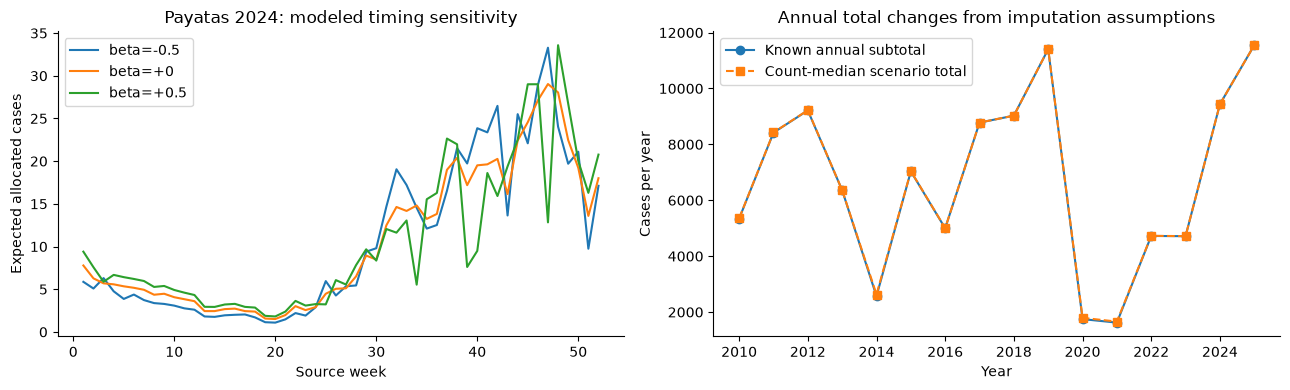

In [16]:
sensitivity_frames = {0.5: source_weekly}
sensitivity_rows = []
for beta in [-.5, 0.0]:
    frame, margins = allocate(annual, settlement, weekly, beta=beta, lag=4)
    sensitivity_frames[beta] = frame
base = sensitivity_frames[0.0].set_index(["barangay_code", "year", "source_week"])
for beta, frame in sensitivity_frames.items():
    aligned = frame.set_index(["barangay_code", "year", "source_week"]).reindex(base.index)
    diff = aligned.synthetic_expected_cases - base.synthetic_expected_cases
    sensitivity_rows.append({"scenario": f"beta={beta:+g}", "sum_abs_expected_difference_from_beta0": diff.abs().sum(),
                             "largest_expected_cell_difference": diff.abs().max()})
master_for_allocation = gis_joined[["barangay_code", "year", "settlement_proportion", "source_barangay_code", "identifier_method"]].copy()
master_for_allocation["value_status"] = "satellite_derived_unharmonized_products"
master_weekly, _ = allocate(annual, master_for_allocation, weekly, beta=.5, lag=4)
tracker_index = source_weekly.set_index(["barangay_code", "year", "source_week"])
master_index = master_weekly.set_index(["barangay_code", "year", "source_week"]).reindex(tracker_index.index)
product_sensitivity = (master_index.synthetic_expected_cases - tracker_index.synthetic_expected_cases).abs().groupby(level="year").agg(["sum", "max"])
assert product_sensitivity.loc[2016:, "max"].max() < 1e-7
sensitivity_summary = pd.DataFrame(sensitivity_rows)
display(sensitivity_summary)
display(product_sensitivity.rename(columns={"sum": "sum_abs_cell_difference", "max": "max_cell_difference"}))
example_code = annual.loc[annual.barangay_name.map(clean_name).eq("payatas"), "barangay_code"].iloc[0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for beta in [-.5, 0, .5]:
    group = sensitivity_frames[beta].loc[lambda f: f.barangay_code.eq(example_code) & f.year.eq(2024)].sort_values("source_week")
    axes[0].plot(group.source_week, group.synthetic_expected_cases, label=f"beta={beta:+g}")
axes[0].set(title="Payatas 2024: modeled timing sensitivity", xlabel="Source week", ylabel="Expected allocated cases")
axes[0].legend()
axes[1].plot(source_margins.year, source_margins.annual_total_used, "o-", label="Known annual subtotal")
axes[1].plot(median_margins.year, median_margins.annual_total_used, "s--", label="Count-median scenario total")
axes[1].set(title="Annual total changes from imputation assumptions", xlabel="Year", ylabel="Cases per year")
axes[1].legend(); plt.tight_layout(); plt.show()


## 14. Export derived data and an audit manifest

Outputs go only to `data/processed/weekly_barangay_reconstruction/`. The original Drive files and pinned UPRI bytes remain unchanged. Gzip timestamps are fixed for repeatable data hashes. The manifest records source hashes/URLs, transformation code hashes, software versions, method settings, null counts and output hashes. The generated weekly files have per-row geography, units, source-year `asOf`, scenario/version, measurement kind and annual-input status; shared source details resolve through the manifest.

Main files:

- `weekly_source_preserving.csv.gz`: source nulls preserved; synthetic integer and expected weekly counts with scaled QC targets.
- `weekly_count_median_scenario.csv.gz`: separate assumption scenario; raw blanks and imputation flags retained.
- `annual_recovery_count_median.csv`, `annual_recovery_share_median.csv`: observed and assumed totals, exact donor years/counts, unrounded estimates and donor IQR.
- Missingness, cross-source reconciliation, margin checks, masking predictions/scores, source-choice and beta-sensitivity tables, plus `manifest.json`.

**Use limits:** no observed weekly barangay targets, no verified reporting dates, no population-denominator incidence, no independent raster validation, no calibrated imputation uncertainty and no proof of causal settlement/rainfall effects. Independent masks assess annual recovery under their chosen missingness pattern only. Preserve original unknowns when presenting observed-source analyses. Seek corrected source records or an independent weekly barangay series before making surveillance or prospective accuracy claims.


In [17]:
if EXPORT:
    OUT.mkdir(parents=True, exist_ok=True)
    tables = {
        "weekly_source_preserving.csv.gz": source_weekly,
        "weekly_count_median_scenario.csv.gz": median_weekly,
        "annual_recovery_count_median.csv": count_recovery,
        "annual_recovery_share_median.csv": share_recovery,
        "annual_missing_entries.csv": missing_annual,
        "annual_qc_reconciliation.csv": reconciliation.reset_index(),
        "weather_missingness.csv": weather_missing,
        "gis_missingness.csv": gis_missing.reset_index(names="field"),
        "gis_identifier_crosswalk.csv": gis_joined[["barangay_name", "barangay_code", "source_barangay_code", "identifier_method"]].drop_duplicates(),
        "margin_checks_source_preserving.csv": source_margins,
        "margin_checks_count_median.csv": median_margins,
        "masking_predictions.csv": mask_predictions,
        "masking_scores.csv": mask_scores,
        "beta_sensitivity.csv": sensitivity_summary,
        "settlement_product_sensitivity.csv": product_sensitivity.reset_index(),
    }
    for filename, frame in tables.items():
        compression = {"method": "gzip", "mtime": 0} if filename.endswith(".gz") else None
        frame.to_csv(OUT / filename, index=False, float_format="%.12g", compression=compression)
    code_inputs = ["scripts/generate_weekly_barangay.py", "notebooks/06_weekly_barangay_reconstruction.ipynb"]
    # Hash cell sources rather than outputs/execution counters to avoid a self-referential notebook hash.
    notebook = json.loads((ROOT / code_inputs[1]).read_text())
    notebook_sources = json.dumps([{"cell_type": c["cell_type"], "source": "".join(c["source"])} for c in notebook["cells"]], ensure_ascii=False, sort_keys=True)
    transform_hashes = {code_inputs[0]: hashlib.sha256((ROOT / code_inputs[0]).read_bytes()).hexdigest(),
                        code_inputs[1] + "#cell-sources": hashlib.sha256(notebook_sources.encode()).hexdigest()}
    source_inputs = [{"path": s["path"], "sha256": s["sha256"], "sourceUrl": s["sourceUrl"]} for s in upri_manifest["sources"]]
    source_inputs += [{"path": s["path"], "sha256": s["sha256"], "sourceUrl": s["url"]} for s in drive_manifest["sources"]]
    source_inputs += [{"path": "data/reference/upri_noah/barangay-crosswalk.json", "sha256": hashlib.sha256((ROOT / "data/reference/upri_noah/barangay-crosswalk.json").read_bytes()).hexdigest(), "sourceUrl": None}]
    output_manifest = {
        "schemaVersion": "1.0", "assumptionVersion": ASSUMPTION_VERSION, "sourceAcquiredDate": "2026-11-20",
        "geography": "Quezon City; 142 source barangay IDs", "years": [2010, 2025],
        "measurementKind": "modeled_allocation", "units": "cases per source block", "sourceCalendar": "52 source blocks per year; exact ISO dates unresolved",
        "status": "retrospective reconstruction; not observed weekly surveillance or prospective forecasts",
        "settings": {"beta": .5, "rainfallLagSourceBlocks": 4, "standardizationDdof": 0, "missingLagInteraction": "neutral z=0, flagged; raw rainfall not imputed",
                     "ipfAbsoluteTolerance": 1e-8, "ipfMaxIterations": 10000, "weeklyTargets": "largest remainder of QC profile scaled to annual known/assumed subtotal",
                     "rounding": "floor plus min-cost transportation increments; HiGHS dual simplex", "medianMinimumObservedDonors": 3,
                     "medianIntegerRounding": "floor(value+0.5)", "medianDonorPolicy": "retrospective other observed years; no chained imputation", "maskSeeds": SEEDS},
        "software": {"python": platform.python_version(), **versions}, "transformHashes": transform_hashes,
        "inputs": source_inputs, "referenceComparison": reference_check,
        "nullCounts": {"annualSource": int(annual.annual_cases.isna().sum()), "weeklySourcePreserving": int(source_weekly.synthetic_cases.isna().sum()),
                       "weeklyMedianScenario": int(median_weekly.synthetic_cases.isna().sum())},
        "limitations": ["Incompatible observed annual/city totals; weekly trial targets are scaled", "Unknown weekly barangay truth", "Same-year/future inputs: retrospective only",
                        "2010–2015 Tracker-scale settlement is extrapolated", "Original Evolution/Tracker master is not harmonized",
                        "Median estimates are assumptions; donor spread is not an interval", "Public redistribution terms must be checked"],
        "outputs": [{"path": p.relative_to(ROOT).as_posix(), "bytes": p.stat().st_size, "sha256": hashlib.sha256(p.read_bytes()).hexdigest(), "rows": len(tables[p.name])}
                    for p in sorted(OUT.iterdir()) if p.name in tables],
    }
    (OUT / "manifest.json").write_text(json.dumps(output_manifest, indent=2, allow_nan=False) + "\n")
    display(pd.DataFrame(output_manifest["outputs"])[["path", "rows", "bytes", "sha256"]])
    print("Wrote", len(tables), "derived data tables and manifest. Raw-source hash checks:")
    verify_sources(ROOT)
    for s in drive_manifest["sources"]:
        assert hashlib.sha256((ROOT / s["path"]).read_bytes()).hexdigest() == s["sha256"]
    print("All original raw bytes preserved.")
else:
    print("EXPORT=False: no derived files written.")


,path,rows,bytes,sha256
0,data/processed/weekly_barangay_reconstruction/...,39,1228,6ccb5201d7a12d07275b31a9acb5a0dc9327383e477e9d...
1,data/processed/weekly_barangay_reconstruction/...,16,857,8602a677e8a19c2605f0b8e548f146ce884f902cb837cf...
2,data/processed/weekly_barangay_reconstruction/...,2272,152405,20a93607b3522a4d71871400328710d38767b5aa4816ed...
3,data/processed/weekly_barangay_reconstruction/...,2272,153257,cc6d8dca6effff3bfe3fdb9d74fa6ff4366168fe4fc51e...
4,data/processed/weekly_barangay_reconstruction/...,3,169,2c54decb92e8116115b75871bfa04601ec2b9dea7a5d96...
5,data/processed/weekly_barangay_reconstruction/...,142,7184,cbbc0c8039ecf546abd20b8d1ec11a9b5ae5929f9167f7...
6,data/processed/weekly_barangay_reconstruction/...,32,757,5df47d30149827f8c180aa6304a6fe9112e3479d461200...
7,data/processed/weekly_barangay_reconstruction/...,16,1239,bfa6f64f3ca5234d78a01cc36300360487fd396b92e23a...
8,data/processed/weekly_barangay_reconstruction/...,16,1239,39dc26747b3454ad4dc7d053a9735fefd3766fa664f62f...
9,data/processed/weekly_barangay_reconstruction/...,2329,149640,0eb5cc8e4a38fedf48d71f829d02a27444483760bc9a24...


Wrote 15 derived data tables and manifest. Raw-source hash checks:
All original raw bytes preserved.


## 15. References and next evidence needed

- **UPRI source version:** Matavia et al. (2026), *Weekly dengue incidence linked to meteorological variables at city, regional, and multi-setting scales*, [pinned repository commit](https://github.com/pelitro-rcw/dengue-environmental-dataset/tree/02926278d570db8950da368d44db544ae0097615). Consult the preserved README and `data/reference/upri_noah/sources.json` for authorship/licensing. Exact hashes establish this notebook's version; a citation alone does not certify matching bytes.
- **Supplied GIS/experiment methodology:** preserved `data/raw/gis_settlements/RESULTS_AND_METHOD.md`, `TRACKER_BACKCAST_METHOD.md`, `START_HERE.md`, and `data/raw/weekly_barangay_synthetic/metadata.json` / `SELECTED_SCENARIO_beta_0_5.md`. Original Drive URLs and acquisition date are recorded in `drive-sources.json`.
- MindEarth / German Aerospace Center. (n.d.). [*World Settlement Footprint Tracker GeoZarr*](https://source.coop/mindearth/wsf). Provider describes 10 m, six-month observations from July 2016. The project annual labels and pre-2016 backcast are additional transformations.
- Australian Bureau of Statistics. (2009). [*The iterative proportional fitting procedure*, Appendix 5](https://www.abs.gov.au/ausstats/abs@.nsf/Products/3228.0.55.001~2009~Appendix~The%20iterative%20proportional%20fitting%20procedure%20(Appendix)).
- National Institute of Standards and Technology. (n.d.). [*Measures of scale*](https://www.itl.nist.gov/div898/handbook/eda/section3/eda356.htm). Robust donor spread does not itself calibrate missing-value uncertainty.
- SciPy community. (n.d.). [*scipy.optimize.linprog*](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html). Installed version is recorded above; online documentation may describe a newer version.

All linked provider/statistical pages above were consulted on 20 November 2026. The inaccessible Evolution provider page is preserved as an upstream reference in the supplied GIS method; no independent provider-page verification or raster re-extraction is claimed here.

**Next evidence to seek:** source correction notes explaining annual/city discrepancies; the actual values behind blank annual cells; verified source calendar and reporting dates; independent barangay weekly counts; and comparable settlement reference data across the product transition. Until then, retain the original missingness and present all generated weekly counts as scenarios.
